In [93]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# 1. Análise Exploratória dos dados (EDA)

In [94]:
df = pd.read_csv(r"../../data/california.csv")

print("Foma do dataframe: ", df.shape)
df.head()

Foma do dataframe:  (20433, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129,322,126,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21,7099,1106,2401,1138,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52,1467,190,496,177,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52,1274,235,558,219,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52,1627,280,565,259,3.8462,342200.0,NEAR BAY


In [95]:
print("Colunas:")
df.columns

Colunas:


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [96]:
print("Tipo dos dados:\n")
print(df.dtypes)

Tipo dos dados:

longitude             float64
latitude              float64
housing_median_age      int64
total_rooms             int64
total_bedrooms          int64
population              int64
households              int64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


In [97]:
print("Tipo de features cattegóricas: ")
df["ocean_proximity"].unique()

Tipo de features cattegóricas: 


<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

## 1.1 Distribuição das variáveis

Métricas de housing_median_age
  Média:          28.63
  Mediana:        29.00
  Moda:           52.00
  Desvio padrão:  12.59
  Skewness:       0.06
  Kurtosis:       -0.80


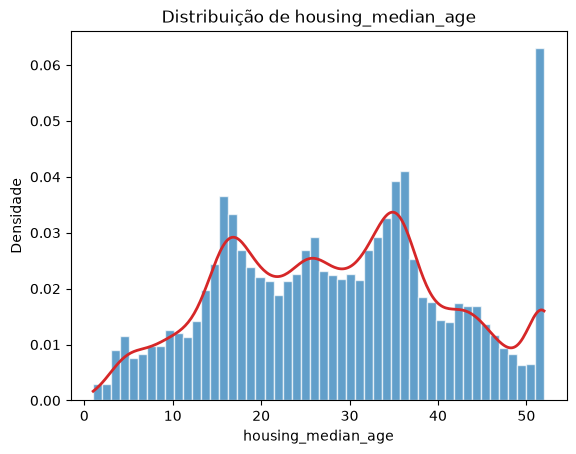

Métricas de median_income
  Média:          3.87
  Mediana:        3.54
  Moda:           3.12
  Desvio padrão:  1.90
  Skewness:       1.64
  Kurtosis:       4.94


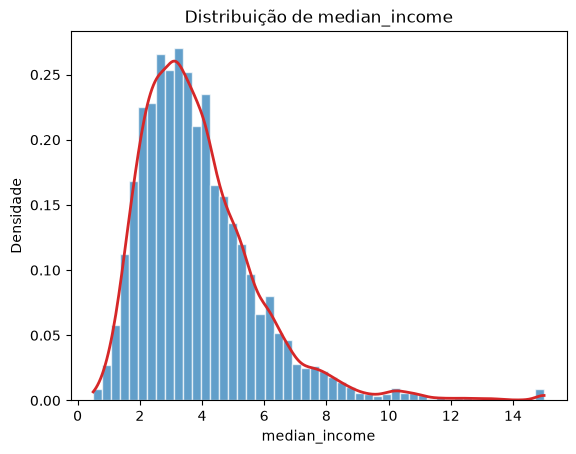

Métricas de total_rooms
  Média:          2636.50
  Mediana:        2127.00
  Moda:           1527.00
  Desvio padrão:  2185.27
  Skewness:       4.16
  Kurtosis:       32.71


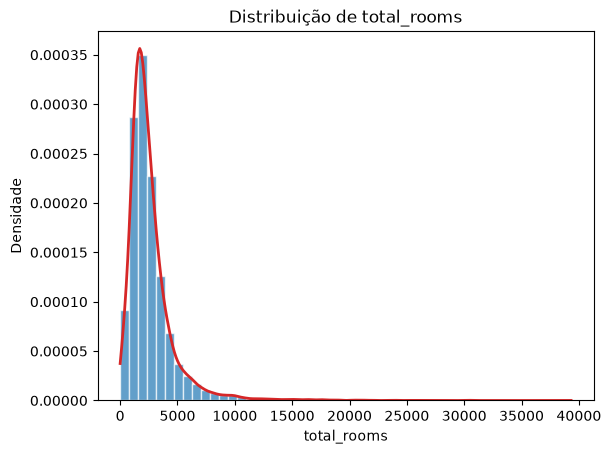

Métricas de total_bedrooms
  Média:          537.87
  Mediana:        435.00
  Moda:           280.00
  Desvio padrão:  421.39
  Skewness:       3.46
  Kurtosis:       21.99


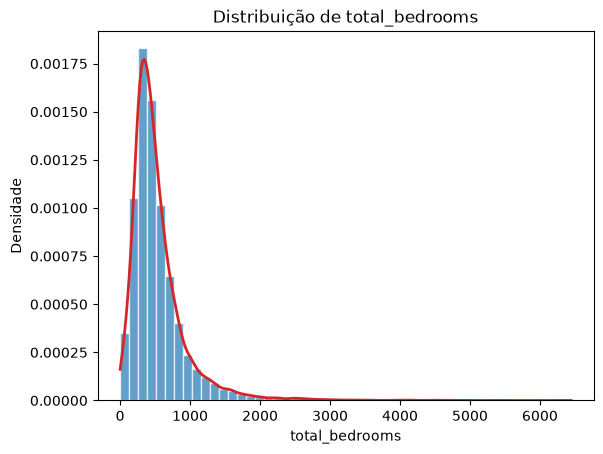

Métricas de population
  Média:          1424.95
  Mediana:        1166.00
  Moda:           891.00
  Desvio padrão:  1133.21
  Skewness:       4.96
  Kurtosis:       74.06


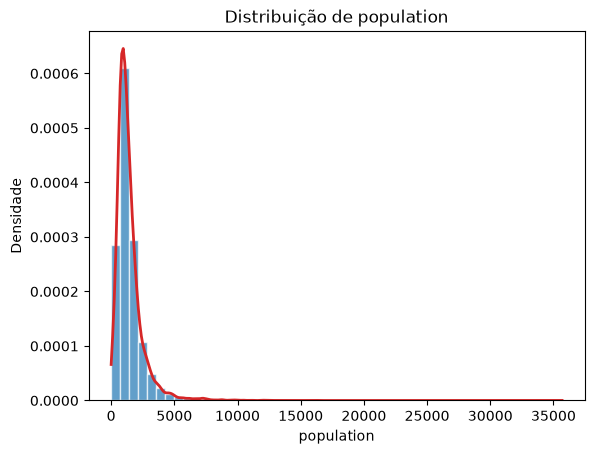

Métricas de households
  Média:          499.43
  Mediana:        409.00
  Moda:           306.00
  Desvio padrão:  382.30
  Skewness:       3.41
  Kurtosis:       22.09


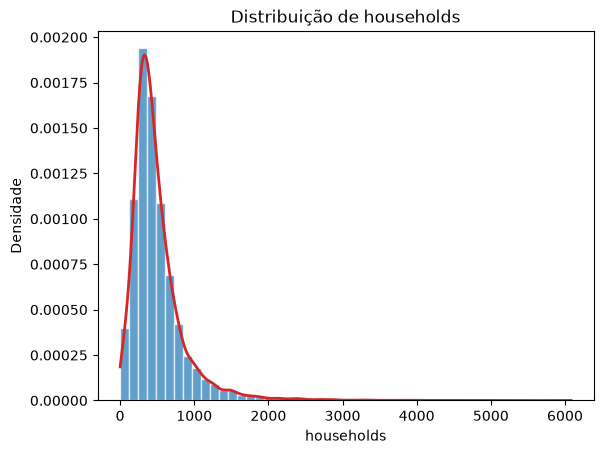

Métricas de median_house_value
  Média:          206864.41
  Mediana:        179700.00
  Moda:           500001.00
  Desvio padrão:  115435.67
  Skewness:       0.98
  Kurtosis:       0.33


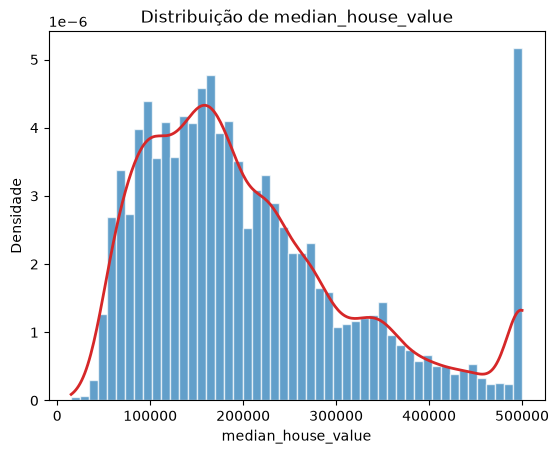

In [98]:
from scipy.stats import gaussian_kde

variaveis_numericas = ["housing_median_age", "median_income", "total_rooms", "total_bedrooms",
                       "population", "households", "median_house_value"]

# Variáveis numéricas: métricas descritivas + histogramas com curva de densidade (KDE)
for col in variaveis_numericas:
    valores = df[col]

    print(f"Métricas de {col}")
    print(f"  Média:          {valores.mean():.2f}")
    print(f"  Mediana:        {valores.median():.2f}")
    print(f"  Moda:           {valores.mode()[0]:.2f}")
    print(f"  Desvio padrão:  {valores.std():.2f}")
    print(f"  Skewness:       {valores.skew():.2f}")   # assimetria: > 0 cauda à direita, < 0 cauda à esquerda
    print(f"  Kurtosis:       {valores.kurt():.2f}")   # excesso de curtose: 0 = normal, > 0 caudas pesadas

    eixo_x = np.linspace(valores.min(), valores.max(), 300)

    plt.hist(valores, bins=50, density=True, edgecolor="white", alpha=0.7)
    plt.plot(eixo_x, gaussian_kde(valores)(eixo_x), color="tab:red", linewidth=2)

    plt.xlabel(col)
    plt.ylabel("Densidade")
    plt.title(f"Distribuição de {col}")
    plt.show()

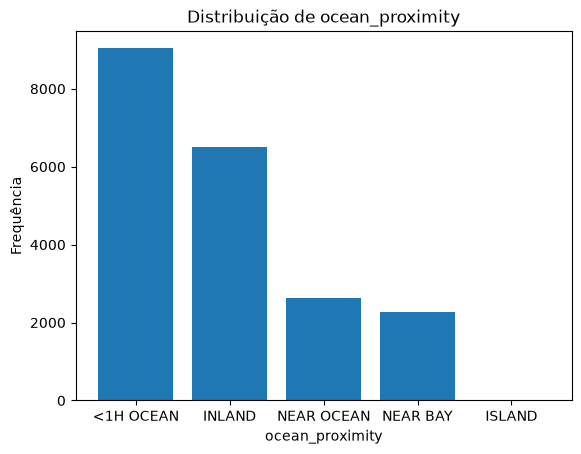

In [99]:
# Variável categórica: contagem por categoria
contagem = df["ocean_proximity"].value_counts()

plt.bar(contagem.index, contagem.values)
plt.xlabel("ocean_proximity")
plt.ylabel("Frequência")
plt.title("Distribuição de ocean_proximity")
plt.show()

### Conclusões da seção 1.1

**`housing_median_age`** é aproximadamente simétrica (média de 28,6 e mediana de 29 anos), com picos perto de 17 e 35 anos. O pico isolado em **52 anos** mostra que a variável foi, provavelmente, **truncada** (todos os distritos com 52 anos ou mais foram registrados como 52).

**`median_income`** é **assimétrica à direita** (média de 3,87 contra mediana de 3,54): a maioria dos distritos tem renda entre 2,6 e 4,7, com uma cauda longa de distritos ricos. Também há um pequeno acúmulo no teto de **15**.

**`total_rooms`, `total_bedrooms`, `population` e `households`** têm o mesmo formato: **fortemente assimétricas à direita**, com quase todos os distritos concentrados nos valores baixos e uma cauda muito longa.

| Variável | Mediana | Máximo | Skewness | Kurtosis |
| --- | --- | --- | --- | --- |
| `total_rooms` | 2.127 | 39.320 | 4,16 | 32,7 |
| `total_bedrooms` | 435 | 6.445 | 3,46 | 22,0 |
| `population` | 1.166 | 35.682 | 4,96 | 74,1 |
| `households` | 409 | 6.082 | 3,41 | 22,1 |

- A **kurtosis muito alta** (de 22 a 74) indica poucos distritos extremamente grandes: o máximo de `population` é cerca de 30 vezes a mediana. Por isso os histogramas parecem "espremidos" à esquerda.
- As quatro são **contagens totais por distrito**, então medem principalmente o **tamanho do distrito**, e não as características das casas. Elas são **muito correlacionadas entre si** (de 0,86 a 0,98; `total_bedrooms` × `households` = 0,98), o que significa que carregam quase a mesma informação.

**`median_house_value`** (o target) também é **assimétrica à direita**, concentrada entre US$ 120 mil e US$ 265 mil. O pico em **US$ 500.001** reúne **4,7% dos distritos**: o valor foi limitado na coleta, então esses imóveis valem "500 mil ou mais", e nenhum modelo conseguirá prever valores acima disso.

**`ocean_proximity`** é **desbalanceada**: `<1H OCEAN` (9.034) e `INLAND` (6.496) somam mais de 75% dos distritos, enquanto `ISLAND` tem **apenas 5 observações**. Na divisão 50/50 em treino e teste, essa categoria pode ficar inteira de um lado só.

## 1.2 Relação das variáveis com o preço dos imóveis (`median_house_value`)

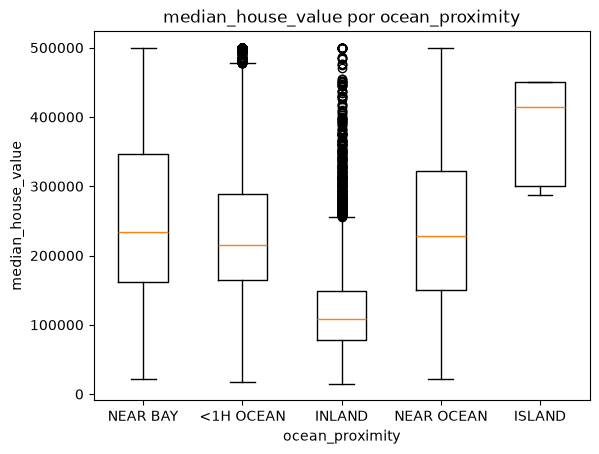

In [100]:
categorias = df["ocean_proximity"].unique()

plt.boxplot([df.loc[df["ocean_proximity"] == c, "median_house_value"] for c in categorias],
            tick_labels=categorias)
plt.xlabel("ocean_proximity")
plt.ylabel("median_house_value")
plt.title("median_house_value por ocean_proximity")
plt.show()

housing_median_age vs. median_house_value
  Correlação:  0.106
  Covariância: 154,704


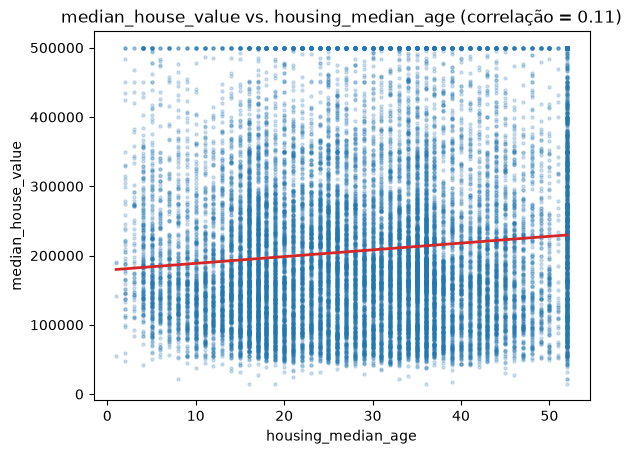

median_income vs. median_house_value
  Correlação:  0.688
  Covariância: 150,919


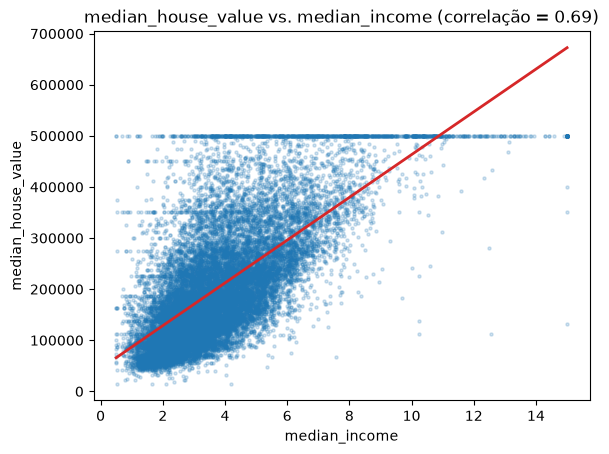

total_rooms vs. median_house_value
  Correlação:  0.133
  Covariância: 33,624,519


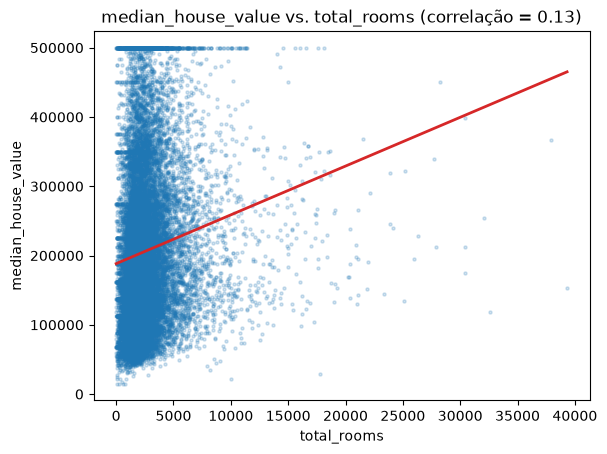

total_bedrooms vs. median_house_value
  Correlação:  0.050
  Covariância: 2,416,878


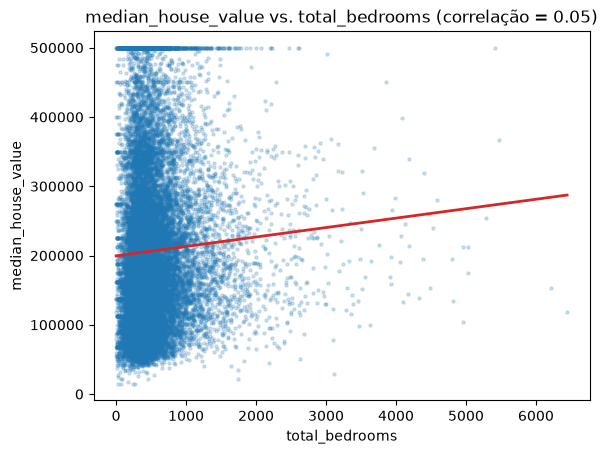

population vs. median_house_value
  Correlação:  -0.025
  Covariância: -3,309,526


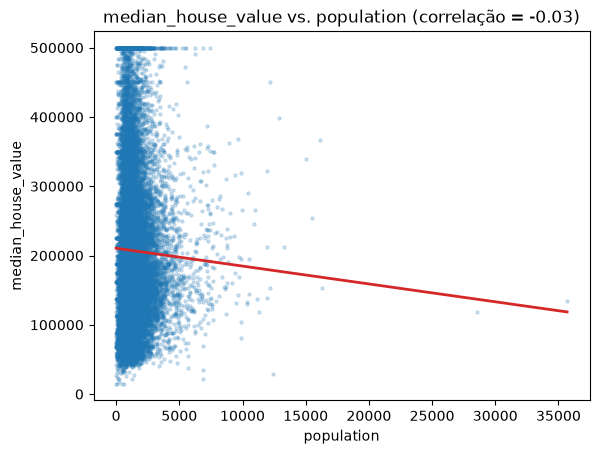

households vs. median_house_value
  Correlação:  0.065
  Covariância: 2,863,815


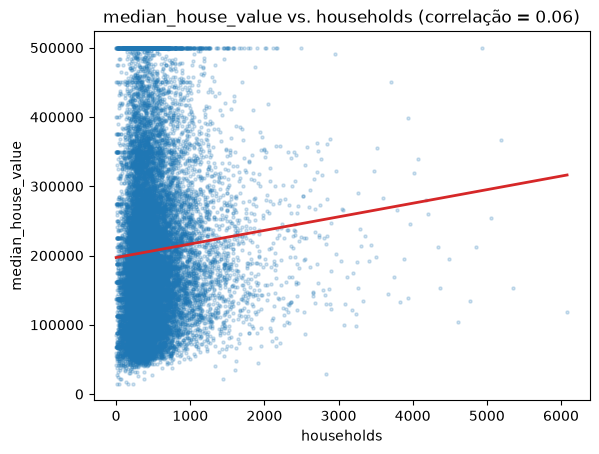

In [101]:
# Variáveis numéricas vs. target: dispersão com linha de tendência (reta de mínimos quadrados)
for col in ["housing_median_age", "median_income", "total_rooms", "total_bedrooms", "population", "households"]:
    x, y = df[col], df["median_house_value"]
    a, b = np.polyfit(x, y, 1)

    print(f"{col} vs. median_house_value")
    print(f"  Correlação:  {x.corr(y):.3f}")    # adimensional, entre -1 e 1: comparável entre variáveis
    print(f"  Covariância: {x.cov(y):,.0f}")    # depende das unidades de x e y: NÃO comparável entre variáveis

    plt.scatter(x, y, s=5, alpha=0.2)
    plt.plot(x.sort_values(), a * x.sort_values() + b, color="tab:red", linewidth=2)

    plt.xlabel(col)
    plt.ylabel("median_house_value")
    plt.title(f"median_house_value vs. {col} (correlação = {x.corr(y):.2f})")
    plt.show()

### Conclusões da seção 1.2

**`ocean_proximity` (box plot)**
- **A localização diferencia bem o preço.** Distritos `INLAND` (interior) são os mais baratos, com mediana de **US$ 108,7 mil**, menos da metade das categorias do litoral.
- **`<1H OCEAN`, `NEAR OCEAN` e `NEAR BAY` são parecidas**, com medianas entre US$ 215 mil e US$ 234 mil e caixas sobrepostas. A distinção relevante é "interior vs. litoral".
- **`INLAND` tem muitos outliers acima de US$ 255 mil**, então a localização sozinha não explica todo o preço. `ISLAND` tem a maior mediana (US$ 414,7 mil), mas com só 5 observações essa estimativa é pouco confiável.

**Variáveis numéricas (dispersão, correlação e covariância)**

| Variável | Correlação | Covariância |
| --- | --- | --- |
| `median_income` | **0,688** | 150.919 |
| `total_rooms` | 0,133 | **33.624.519** |
| `housing_median_age` | 0,106 | 154.704 |
| `households` | 0,065 | 2.863.815 |
| `total_bedrooms` | 0,050 | 2.416.878 |
| `population` | −0,025 | −3.309.526 |

**Correlação vs. covariância**
- As duas medem se `x` e `y` variam **juntas** e têm o **mesmo sinal**: positivo quando crescem juntas, negativo quando uma cresce e a outra cai. Só `population` tem sinal negativo, e mesmo assim muito fraco.
- A **covariância depende das unidades** das variáveis: $\text{cov}(x, y) = \text{corr}(x, y) \cdot s_x \cdot s_y$. Por isso ela **não serve para comparar variáveis**. A tabela mostra isso: `total_rooms` tem a **maior** covariância (33,6 milhões) só porque seus valores são enormes (desvio padrão de 2.185), embora a relação com o preço seja fraca. Já `median_income`, a variável mais associada ao preço, tem covariância **menor** que `housing_median_age`, porque a renda é medida em uma escala pequena (desvio padrão de 1,9).
- A **correlação** divide a covariância pelos desvios padrão, fica entre −1 e 1 e **não depende das unidades**. É ela que deve ser usada para comparar a força das relações.

**`median_income`**
- **É a variável mais associada ao preço** (correlação de **0,69**). A relação é clara e crescente: a mediana do preço sobe de US$ 93 mil para distritos com renda até 2 para US$ 336 mil com renda entre 6 e 8.
- **A reta de tendência ultrapassa o teto de US$ 500.001** a partir de renda ≈ 11. Acima disso, os pontos formam uma linha horizontal no teto: o truncamento do target "achata" a relação para as rendas mais altas, e uma regressão linear superestimaria esses preços.
- A dispersão vertical é grande para uma mesma renda, então outras variáveis, como a localização, ajudam a explicar o restante.

**`housing_median_age`**
- **Quase não tem relação linear com o preço** (correlação de **0,11**). Os pontos ocupam toda a faixa de preços para qualquer idade, e a linha de tendência é quase plana.
- A exceção é o grupo truncado em **52 anos**, com mediana de US$ 259 mil contra cerca de US$ 170 mil a US$ 185 mil nas outras faixas. Provavelmente são bairros antigos e centrais das grandes cidades. Esse efeito não é linear e tende a ser mais bem capturado por árvores.

**`total_rooms`, `total_bedrooms`, `population` e `households`**
- **Praticamente não têm relação com o preço**: as correlações ficam entre −0,03 e 0,13, apesar das covariâncias de milhões, que refletem só a escala das contagens. Os pontos formam uma "parede" vertical perto de zero, cobrindo toda a faixa de preços.
- As **linhas de tendência são enganosas**: a inclinação é definida por poucos distritos gigantes na cauda direita, e não pela massa de dados. É um exemplo de como outliers distorcem a regressão linear.
- Isso faz sentido: são contagens que medem o **tamanho** do distrito, e um distrito grande não é necessariamente caro. Para essas variáveis informarem algo sobre o preço, seria preciso transformá-las em **razões**, como cômodos por domicílio ou quartos por cômodo.

**Em todos os gráficos** aparece a faixa horizontal no teto de **US$ 500.001**, presente em todas as faixas de renda e idade. Isso reforça o efeito do truncamento visto na seção 1.1.

# 2. Feature Engineering

Criação de três novas variáveis a partir das contagens totais por distrito:

| Nova variável | Fórmula | O que representa |
| --- | --- | --- |
| `bedrooms_per_room` | `total_bedrooms / total_rooms` | Quartos por cômodo |
| `rooms_per_household` | `total_rooms / households` | Cômodos por domicílio |
| `population_per_household` | `population / households` | Pessoas por domicílio |

In [102]:
# Cópia do dataframe para a análise exploratória das novas variáveis
# (o df original fica intacto: no tópico 3 essas variáveis são criadas dentro do pipeline)
df_fe = df.copy()

df_fe["bedrooms_per_room"] = df_fe["total_bedrooms"] / df_fe["total_rooms"]
df_fe["rooms_per_household"] = df_fe["total_rooms"] / df_fe["households"]
df_fe["population_per_household"] = df_fe["population"] / df_fe["households"]

df_fe[["bedrooms_per_room", "rooms_per_household", "population_per_household"]].describe()

,bedrooms_per_room,rooms_per_household,population_per_household
count,20433.000000,20433.000000,20433.000000
mean,0.213039,5.431344,3.071533
std,0.057983,2.482946,10.438269
min,0.100000,0.846154,0.692308
25%,0.175427,4.441441,2.429032
50%,0.203162,5.230769,2.817582
75%,0.239821,6.052381,3.281513
max,1.000000,141.909091,1243.333333


bedrooms_per_room vs. median_house_value
  Correlação:  -0.256
  Covariância: -1,713


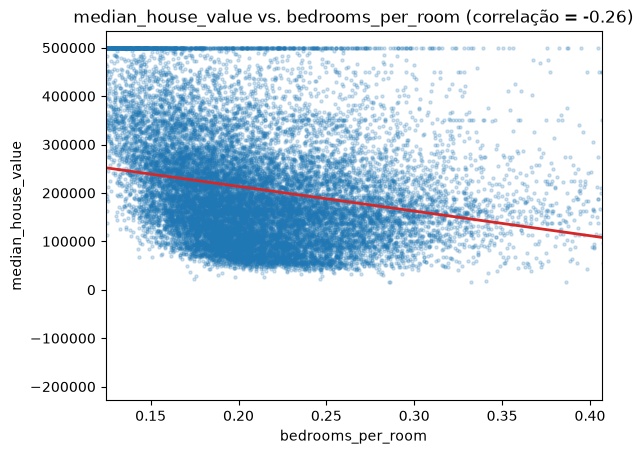

rooms_per_household vs. median_house_value
  Correlação:  0.151
  Covariância: 43,378


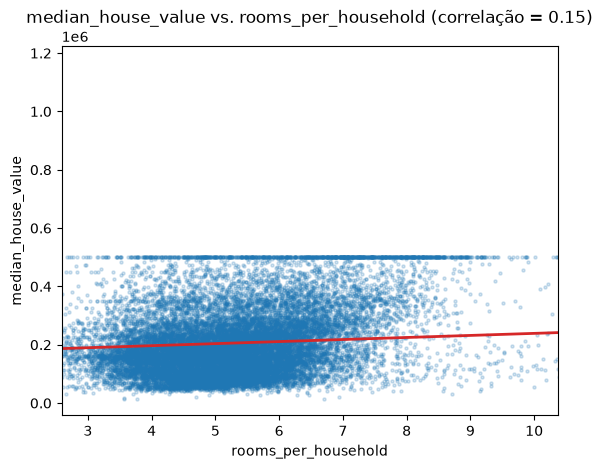

population_per_household vs. median_house_value
  Correlação:  -0.024
  Covariância: -28,484


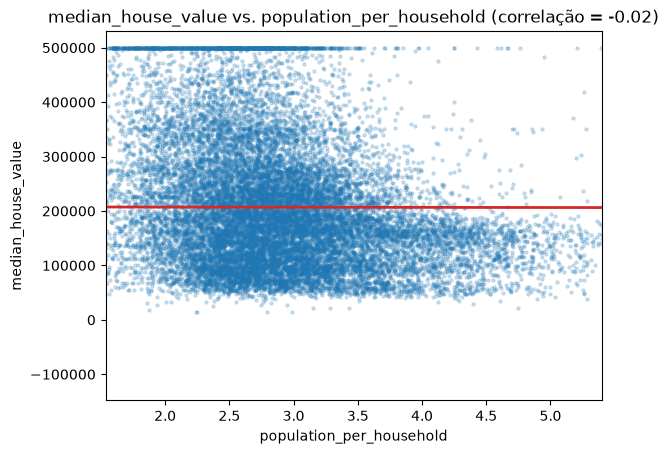

In [103]:
# Novas variáveis vs. target: dispersão com linha de tendência (reta de mínimos quadrados)
for col in ["bedrooms_per_room", "rooms_per_household", "population_per_household"]:
    x, y = df_fe[col], df_fe["median_house_value"]
    a, b = np.polyfit(x, y, 1)

    print(f"{col} vs. median_house_value")
    print(f"  Correlação:  {x.corr(y):.3f}")    # adimensional, entre -1 e 1: comparável entre variáveis
    print(f"  Covariância: {x.cov(y):,.0f}")    # depende das unidades de x e y: NÃO comparável entre variáveis

    plt.scatter(x, y, s=5, alpha=0.2)
    plt.plot(x.sort_values(), a * x.sort_values() + b, color="tab:red", linewidth=2)

    # Poucos valores extremos (até 1243 pessoas por domicílio) esmagariam o gráfico:
    # o eixo x mostra só do percentil 1 ao 99 (a reta e as métricas usam todos os dados)
    plt.xlim(x.quantile(0.01), x.quantile(0.99))

    plt.xlabel(col)
    plt.ylabel("median_house_value")
    plt.title(f"median_house_value vs. {col} (correlação = {x.corr(y):.2f})")
    plt.show()

### Conclusões do tópico 2

| Variável | Correlação com o preço |
| --- | --- |
| `bedrooms_per_room` | **−0,256** |
| `rooms_per_household` | 0,151 |
| `population_per_household` | −0,024 |
| *Melhor contagem bruta (`total_rooms`)* | *0,133* |

**`bedrooms_per_room`**
- É a nova variável **mais associada ao preço**: a correlação de −0,26 é o dobro da melhor contagem bruta. Quanto **menor** a fração de cômodos que são quartos, **mais caro** o distrito, porque as casas têm proporcionalmente mais salas, escritórios e outros cômodos, ou seja, são maiores.
- O efeito **não é linear**: os 20% dos distritos com menos quartos por cômodo (até 0,17) têm mediana de **US$ 282 mil**, enquanto os demais ficam entre US$ 153 mil e US$ 182 mil. A relação se concentra nos valores baixos, como um "limiar".
- Ela tem correlação de −0,62 com `median_income`, então parte da informação já está na renda.

**`rooms_per_household`**
- A relação é **positiva** (0,15): mais cômodos por domicílio, casas maiores, preço maior. Também é concentrada no topo: os 20% com mais de 6,3 cômodos por domicílio têm mediana de **US$ 272 mil**, contra cerca de US$ 160 mil a US$ 187 mil nos demais.
- Há valores extremos de **até 142 cômodos por domicílio**, provavelmente áreas de casas de veraneio ou com poucos moradores fixos. Esses pontos puxam a reta de tendência.

**`population_per_household`**
- A correlação linear é quase **zero (−0,02)**, mas isso **engana**. Por faixas, o preço cai de forma consistente: de **US$ 227 mil** nos 20% com menos pessoas por domicílio para **US$ 148 mil** nos 20% mais lotados. Domicílios mais cheios indicam distritos mais pobres.
- A correlação não capta essa relação por causa de poucos outliers gigantes, com **até 1243 pessoas por domicílio** (provavelmente alojamentos coletivos, como dormitórios ou quartéis). É um bom exemplo de que a correlação de Pearson pode esconder uma relação real.

**Resumo:** as três razões têm relações com o preço **mais claras** que as contagens brutas, porém **não lineares**, com efeitos concentrados nos extremos e outliers fortes. Esse é exatamente o cenário em que árvores e Random Forests funcionam bem: os splits dependem só da **ordem** dos valores, então os outliers não distorcem o modelo, e os limiares são capturados naturalmente.

### Por que essas três variáveis?

1. **As contagens brutas medem o tamanho do distrito, não o tipo de imóvel.** `total_rooms`, `total_bedrooms`, `population` e `households` crescem simplesmente porque o distrito é maior, e um distrito grande não é necessariamente caro. Por isso suas correlações com o preço ficam entre −0,03 e 0,13 (seção 1.2). Dividir uma contagem por outra **remove o efeito do tamanho** e descreve o **domicílio típico** do distrito: quantos cômodos ele tem, que fração deles são quartos e quantas pessoas moram nele.
2. **As contagens são redundantes entre si.** As correlações entre elas vão de 0,86 a 0,98 (seção 1.1), então carregam quase a mesma informação. As razões trazem **informação nova**, que não está em nenhuma contagem isolada.
3. **Uma árvore não consegue criar razões sozinha.** Os splits são cortes do tipo `total_rooms <= c`, paralelos aos eixos. Para imitar uma razão como `total_bedrooms / total_rooms`, que é uma fronteira diagonal no plano dessas duas variáveis, a árvore precisaria empilhar muitos cortes em "escada". Entregar a razão pronta permite capturar o mesmo efeito com **um único split**.
4. **Não aplicamos log nem padronização.** Apesar da forte assimetria das contagens, árvores e Random Forests são **invariantes a transformações monótonas**: o log não muda a ordem dos valores, então os splits seriam exatamente os mesmos.

# 3. Pipeline de pré-processamento

O pipeline aplica, em ordem:

1. **Feature engineering:** cria as três razões do tópico 2 (`FunctionTransformer`).
2. **Variáveis numéricas:** preenche valores faltantes com a **mediana** (`SimpleImputer`).
3. **Variável categórica:** preenche valores faltantes com a categoria mais frequente e aplica **one-hot encoding** descartando uma categoria (`OneHotEncoder(drop="first")`).

In [104]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder


# 1. Feature engineering: as mesmas razões do tópico 2, agora como etapa do pipeline
def adicionar_razoes(X):
    X = X.copy()
    X["bedrooms_per_room"] = X["total_bedrooms"] / X["total_rooms"]
    X["rooms_per_household"] = X["total_rooms"] / X["households"]
    X["population_per_household"] = X["population"] / X["households"]
    return X


colunas_numericas = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
                     "population", "households", "median_income",
                     "bedrooms_per_room", "rooms_per_household", "population_per_household"]
colunas_categoricas = ["ocean_proximity"]

# 2 e 3. Tratamento separado para variáveis numéricas e categóricas
transformacoes = ColumnTransformer(
    [
        ("numericas", SimpleImputer(strategy="median"), colunas_numericas),
        ("categoricas", Pipeline([
            ("imputacao", SimpleImputer(strategy="most_frequent")),
            # drop="first": descarta uma categoria para evitar multicolinearidade (armadilha das dummies)
            # handle_unknown="ignore": categoria ausente no treino vira um vetor de zeros no teste
            ("one_hot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), colunas_categoricas),
    ],
    verbose_feature_names_out=False,
)

preprocessamento = Pipeline([
    ("feature_engineering", FunctionTransformer(adicionar_razoes)),
    ("transformacoes", transformacoes),
])

preprocessamento

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('transformacoes', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function adi...x7545a0ed7560>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default

In [105]:
# Apenas para inspecionar o resultado do pipeline.
# Nos modelos (tópicos 4 e 5), o pipeline é ajustado SOMENTE no conjunto de treino.
print("Valores faltantes no dataset original:", df.isna().sum().sum())

X_inspecao = preprocessamento.fit_transform(df.drop(columns=["median_house_value"]))
colunas_finais = preprocessamento.named_steps["transformacoes"].get_feature_names_out()

print("Formato após o pipeline:", X_inspecao.shape)
pd.DataFrame(X_inspecao, columns=colunas_finais).head()

Valores faltantes no dataset original: 0
Formato após o pipeline: (20433, 15)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,bedrooms_per_room,rooms_per_household,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0.146591,6.984127,2.555556,0.0,0.0,1.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0.155797,6.238137,2.109842,0.0,0.0,1.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0.129516,8.288136,2.802260,0.0,0.0,1.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0.184458,5.817352,2.547945,0.0,0.0,1.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0.172096,6.281853,2.181467,0.0,0.0,1.0,0.0


### Decisões do pipeline

- **Mediana em vez de média.** As variáveis numéricas são assimétricas à direita (skewness de até 4,96), e a média é "puxada para cima" pelos poucos distritos gigantes. A mediana representa melhor o distrito típico e não é afetada por outliers. Este dataset já não tem valores faltantes, mas o imputador deixa o pipeline robusto para dados novos.
- **Feature engineering antes da imputação.** Se `total_bedrooms` estiver faltando, `bedrooms_per_room` também fica faltando e é preenchida com a mediana da própria razão, o que é mais coerente do que calcular a razão com um valor inventado.
- **One-hot com `drop="first"`.** As 5 categorias de `ocean_proximity` viram **4 colunas binárias**, e `<1H OCEAN`, a primeira em ordem alfabética, vira a referência (todas as colunas iguais a 0). Com as 5 colunas, elas sempre somariam 1, ficando perfeitamente colineares com o intercepto (a "armadilha das dummies"), o que impede estimar os coeficientes de uma regressão linear. Árvores não sofrem com isso, mas descartar a coluna redundante não perde informação.
- **`handle_unknown="ignore"`.** `ISLAND` tem só 5 observações e pode faltar no treino. Nesse caso, ela vira um vetor de zeros no teste, em vez de gerar um erro.
- **Tudo dentro de um único pipeline.** As medianas e as categorias são aprendidas **só no treino** e aplicadas igualmente ao teste. Isso evita **vazamento de dados** (*data leakage*): informação do teste influenciando o treino.

# 4. Árvore de regressão

In [106]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

# Amostragem estratificada pelo target: divide median_house_value em 10 faixas de mesmo tamanho (decis)
# e garante que treino e teste tenham a mesma proporção de distritos em cada faixa de preço.
# Sem isso, o sorteio aleatório pode concentrar faixas raras (ex.: o teto de US$ 500.001) em um dos lados.
faixas_target = pd.qcut(y, q=10, labels=False, duplicates="drop")

# Divisão 50/50 em treino e teste (random_state fixo para a divisão ser reproduzível)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=faixas_target
)

print("Treino:", X_treino.shape)
print("Teste: ", X_teste.shape)

# Verificação: proporção de distritos em cada faixa de preço, no treino e no teste
faixas_valores = pd.qcut(y, q=10, duplicates="drop")
pd.DataFrame({
    "Treino (%)": faixas_valores.loc[y_treino.index].value_counts(normalize=True).sort_index() * 100,
    "Teste (%)": faixas_valores.loc[y_teste.index].value_counts(normalize=True).sort_index() * 100,
}).round(2)

Treino: (10216, 9)
Teste:  (10217, 9)


,Treino (%),Teste (%)
median_house_value,,
"(14998.999, 82300.0]",10.01,10.02
"(82300.0, 107300.0]",10.01,10.01
"(107300.0, 133900.0]",9.99,9.99
"(133900.0, 157300.0]",9.99,10.00
"(157300.0, 179700.0]",9.98,9.97
"(179700.0, 209400.0]",10.03,10.03
"(209400.0, 241900.0]",9.98,9.98
"(241900.0, 290000.0]",9.98,9.98
"(290000.0, 376680.0]",9.99,9.99


In [107]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.tree import DecisionTreeRegressor


def avaliar(modelo, nome):
    """Calcula RMSE, MAE e R² no treino e no teste."""
    resultado = {"Modelo": nome}
    for conjunto, X_c, y_c in [("treino", X_treino, y_treino), ("teste", X_teste, y_teste)]:
        previsto = modelo.predict(X_c)
        resultado[f"RMSE {conjunto}"] = root_mean_squared_error(y_c, previsto)
        resultado[f"MAE {conjunto}"] = mean_absolute_error(y_c, previsto)
        resultado[f"R² {conjunto}"] = r2_score(y_c, previsto)
    return resultado


# clone() cria uma cópia "zerada" do pipeline, para cada modelo ter o seu próprio pré-processamento
arvore = Pipeline([
    ("preprocessamento", clone(preprocessamento)),
    ("modelo", DecisionTreeRegressor(random_state=42)),
])
arvore.fit(X_treino, y_treino)

resultados = [avaliar(arvore, "Árvore de regressão")]

modelo_arvore = arvore.named_steps["modelo"]
print("Profundidade da árvore:", modelo_arvore.get_depth())
print("Número de folhas:      ", modelo_arvore.get_n_leaves())
pd.DataFrame(resultados).set_index("Modelo").round(3)

Profundidade da árvore: 33
Número de folhas:       9784


,RMSE treino,MAE treino,R² treino,RMSE teste,MAE teste,R² teste
Modelo,,,,,,
Árvore de regressão,0.0,0.0,1.0,73337.118,47423.927,0.597


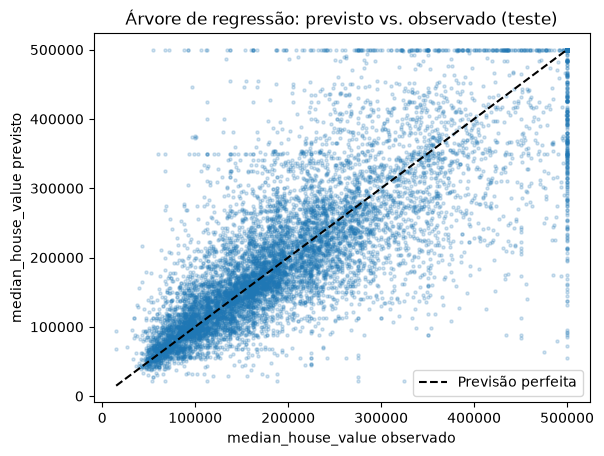

In [108]:
# Valores previstos vs. observados no conjunto de teste
previsto_arvore = arvore.predict(X_teste)

plt.scatter(y_teste, previsto_arvore, s=5, alpha=0.2)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], "k--", label="Previsão perfeita")

plt.xlabel("median_house_value observado")
plt.ylabel("median_house_value previsto")
plt.title("Árvore de regressão: previsto vs. observado (teste)")
plt.legend()
plt.show()

# 5. Random Forest

In [109]:
# Divisão 50/50 em treino e teste, estratificada pelas mesmas faixas de preço do tópico 4.
# O mesmo random_state e a mesma estratificação geram exatamente a mesma divisão,
# o que torna a comparação entre os modelos justa.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=faixas_target
)

print("Treino:", X_treino.shape)
print("Teste: ", X_teste.shape)

Treino: (10216, 9)
Teste:  (10217, 9)


In [110]:
from sklearn.ensemble import RandomForestRegressor

random_forest = Pipeline([
    ("preprocessamento", clone(preprocessamento)),
    ("modelo", RandomForestRegressor(
        n_estimators=300,      # número de árvores da floresta
        max_features=1/3,      # cada split sorteia 1/3 das variáveis (recomendação de Breiman para regressão).
                               # O padrão do sklearn (1.0) usa todas as variáveis, o que seria bagging, não Random Forest
        oob_score=True,        # calcula o erro out-of-bag
        random_state=42,
        n_jobs=-1,             # usa todos os núcleos do processador
    )),
])
random_forest.fit(X_treino, y_treino)

resultados.append(avaliar(random_forest, "Random Forest"))

modelo_rf = random_forest.named_steps["modelo"]
print("R² out-of-bag:  ", round(modelo_rf.oob_score_, 3))
print("RMSE out-of-bag:", round(root_mean_squared_error(y_treino, modelo_rf.oob_prediction_)))
pd.DataFrame(resultados[-1:]).set_index("Modelo").round(3)

R² out-of-bag:   0.815
RMSE out-of-bag: 49648


,RMSE treino,MAE treino,R² treino,RMSE teste,MAE teste,R² teste
Modelo,,,,,,
Random Forest,18285.878,12318.724,0.975,49983.77,33251.75,0.813


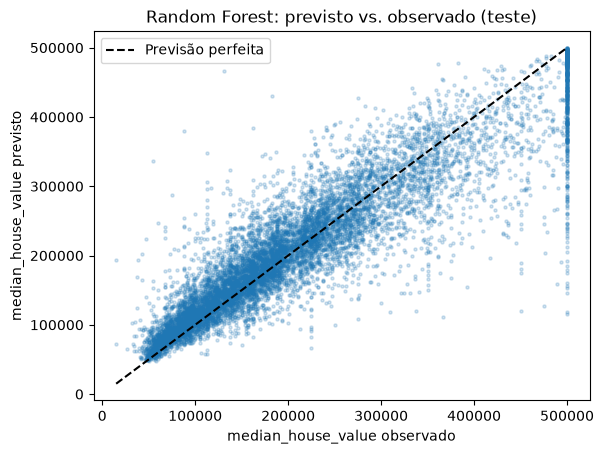

In [111]:
# Valores previstos vs. observados no conjunto de teste
previsto_rf = random_forest.predict(X_teste)

plt.scatter(y_teste, previsto_rf, s=5, alpha=0.2)
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], "k--", label="Previsão perfeita")

plt.xlabel("median_house_value observado")
plt.ylabel("median_house_value previsto")
plt.title("Random Forest: previsto vs. observado (teste)")
plt.legend()
plt.show()

In [112]:
# Comparação entre os dois modelos (mesma divisão treino/teste)
pd.DataFrame(resultados).set_index("Modelo").round(3).T

Modelo,Árvore de regressão,Random Forest
RMSE treino,0.000,18285.878
MAE treino,0.000,12318.724
R² treino,1.000,0.975
RMSE teste,73337.118,49983.770
MAE teste,47423.927,33251.750
R² teste,0.597,0.813
